In [1]:
# ============================================================
# MEMBER 5 — MACHINE LEARNING & FINAL REPORT
# STEPS 71–90
# ============================================================

# Prerequisite: Run Member 2 first. This script loads the cleaned dataset,
# then trains and evaluates models and saves the model/report.

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

INPUT_FILE = (r"C:\Users\admin\OneDrive\Desktop\Hotel Booking Cancellation Prediction & Analysis\output\preprocessing_results\hotel_bookings_cleaned.csv")
OUTPUT_FOLDER = 'output'
PREPROCESSING_FOLDER = os.path.join(OUTPUT_FOLDER, 'preprocessing_results')
EDA_FOLDER = os.path.join(OUTPUT_FOLDER, 'eda_results')
VISUALIZATION_FOLDER = os.path.join(OUTPUT_FOLDER, 'visualization_results')
ML_FOLDER = os.path.join(OUTPUT_FOLDER, 'machine_learning_results')
for folder in [OUTPUT_FOLDER, PREPROCESSING_FOLDER, EDA_FOLDER, VISUALIZATION_FOLDER, ML_FOLDER]:
    os.makedirs(folder, exist_ok=True)

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
CLEANED_FILE = os.path.join(PREPROCESSING_FOLDER, 'hotel_bookings_cleaned.csv')
if not os.path.exists(CLEANED_FILE):
    raise FileNotFoundError('Run Member 2 first; cleaned dataset not found: ' + CLEANED_FILE)
df = pd.read_csv(CLEANED_FILE)
target_column = 'is_canceled'

# ============================================================
# STEP 71 — PREPARE MACHINE LEARNING DATASET
# ============================================================

print("\n" + "=" * 70)
print("STEP 71 — PREPARE MACHINE LEARNING DATASET")
print("=" * 70)

ml_df = df.copy()

y = ml_df[target_column].astype(int)

# Remove target and outcome-leaking columns.
# reservation_status reveals the final reservation outcome.
# arrival_date is a derived date; original date components remain available.

columns_to_drop = [
    "is_canceled",
    "reservation_status",
    "reservation_status_date",
    "arrival_date",
    "arrival_month_num",
    "total_guests"
]

X = ml_df.drop(
    columns=[
        col for col in columns_to_drop
        if col in ml_df.columns
    ]
).copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)


STEP 71 — PREPARE MACHINE LEARNING DATASET
Feature shape: (119390, 31)
Target shape: (119390,)


In [2]:
# ============================================================
# STEP 72 — IDENTIFY ML FEATURES
# ============================================================

print("\n" + "=" * 70)
print("STEP 72 — IDENTIFY ML FEATURES")
print("=" * 70)

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", len(numeric_features))
print(numeric_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)


STEP 72 — IDENTIFY ML FEATURES
Numerical features: 20
['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'total_nights']

Categorical features: 11
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'city']


In [3]:
# ============================================================
# STEP 73 — TRAIN TEST SPLIT
# ============================================================

print("\n" + "=" * 70)
print("STEP 73 — TRAIN TEST SPLIT")
print("=" * 70)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows :", X_test.shape[0])
print("Training features:", X_train.shape[1])


STEP 73 — TRAIN TEST SPLIT
Training rows: 95512
Testing rows : 23878
Training features: 31


In [4]:
# ============================================================
# STEP 74 — NUMERICAL PREPROCESSING PIPELINE
# ============================================================

print("\n" + "=" * 70)
print("STEP 74 — NUMERICAL PREPROCESSING")
print("=" * 70)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Numerical preprocessing pipeline created.")


STEP 74 — NUMERICAL PREPROCESSING
Numerical preprocessing pipeline created.


In [5]:
# ============================================================
# STEP 75 — CATEGORICAL PREPROCESSING PIPELINE
# ============================================================

print("\n" + "=" * 70)
print("STEP 75 — CATEGORICAL PREPROCESSING")
print("=" * 70)

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

print("Categorical preprocessing pipeline created.")


STEP 75 — CATEGORICAL PREPROCESSING
Categorical preprocessing pipeline created.


In [6]:
# ============================================================
# STEP 76 — COMBINE PREPROCESSING PIPELINES
# ============================================================

print("\n" + "=" * 70)
print("STEP 76 — COMBINE PREPROCESSING")
print("=" * 70)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Combined preprocessing pipeline created.")


STEP 76 — COMBINE PREPROCESSING
Combined preprocessing pipeline created.


In [7]:
# ============================================================
# STEP 77 — CREATE BASELINE MODEL
# ============================================================

print("\n" + "=" * 70)
print("STEP 77 — BASELINE MODEL")
print("=" * 70)

models = {
    "Dummy Baseline": DummyClassifier(
        strategy="most_frequent"
    )
}

print("Baseline model created.")


STEP 77 — BASELINE MODEL
Baseline model created.


In [8]:
# ============================================================
# STEP 78 — CREATE LOGISTIC REGRESSION MODEL
# ============================================================

print("\n" + "=" * 70)
print("STEP 78 — LOGISTIC REGRESSION")
print("=" * 70)

models["Logistic Regression"] = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

print("Logistic Regression model created.")


STEP 78 — LOGISTIC REGRESSION
Logistic Regression model created.


In [9]:
# ============================================================
# STEP 79 — CREATE DECISION TREE MODEL
# ============================================================

print("\n" + "=" * 70)
print("STEP 79 — DECISION TREE")
print("=" * 70)

models["Decision Tree"] = DecisionTreeClassifier(
    max_depth=12,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42
)

print("Decision Tree model created.")


STEP 79 — DECISION TREE
Decision Tree model created.


In [10]:
# ============================================================
# STEP 80 — CREATE RANDOM FOREST MODEL
# ============================================================

print("\n" + "=" * 70)
print("STEP 80 — RANDOM FOREST")
print("=" * 70)

models["Random Forest"] = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)

print("Random Forest model created.")


STEP 80 — RANDOM FOREST
Random Forest model created.


In [11]:
# ============================================================
# STEP 81 — TRAIN AND EVALUATE MODELS
# ============================================================

print("\n" + "=" * 70)
print("STEP 81 — TRAIN AND EVALUATE MODELS")
print("=" * 70)

results = []
trained_models = {}

for model_name, model in models.items():

    print("\n" + "-" * 60)
    print("Training model:", model_name)
    print("-" * 60)

    pipeline = Pipeline(steps=[
        ("prep", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    if hasattr(pipeline, "predict_proba"):
        probabilities = pipeline.predict_proba(X_test)[:, 1]
    else:
        probabilities = None

    result = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1_Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC_AUC": (
            roc_auc_score(y_test, probabilities)
            if probabilities is not None else np.nan
        ),
        "PR_AUC": (
            average_precision_score(y_test, probabilities)
            if probabilities is not None else np.nan
        )
    }

    results.append(result)
    trained_models[model_name] = pipeline

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))

results_df = pd.DataFrame(results).sort_values(
    "F1_Score",
    ascending=False
)

print("\nMODEL COMPARISON:")
print(results_df)

results_df.to_csv(
    os.path.join(ML_FOLDER, "step_81_model_comparison.csv"),
    index=False
)


STEP 81 — TRAIN AND EVALUATE MODELS

------------------------------------------------------------
Training model: Dummy Baseline
------------------------------------------------------------

Classification Report:
              precision    recall  f1-score   support

           0       0.63      1.00      0.77     15033
           1       0.00      0.00      0.00      8845

    accuracy                           0.63     23878
   macro avg       0.31      0.50      0.39     23878
weighted avg       0.40      0.63      0.49     23878


------------------------------------------------------------
Training model: Logistic Regression
------------------------------------------------------------

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.83      0.84     15033
           1       0.73      0.78      0.75      8845

    accuracy                           0.81     23878
   macro avg       0.79      0.80      0.80     23878
wei


STEP 82 — MODEL COMPARISON


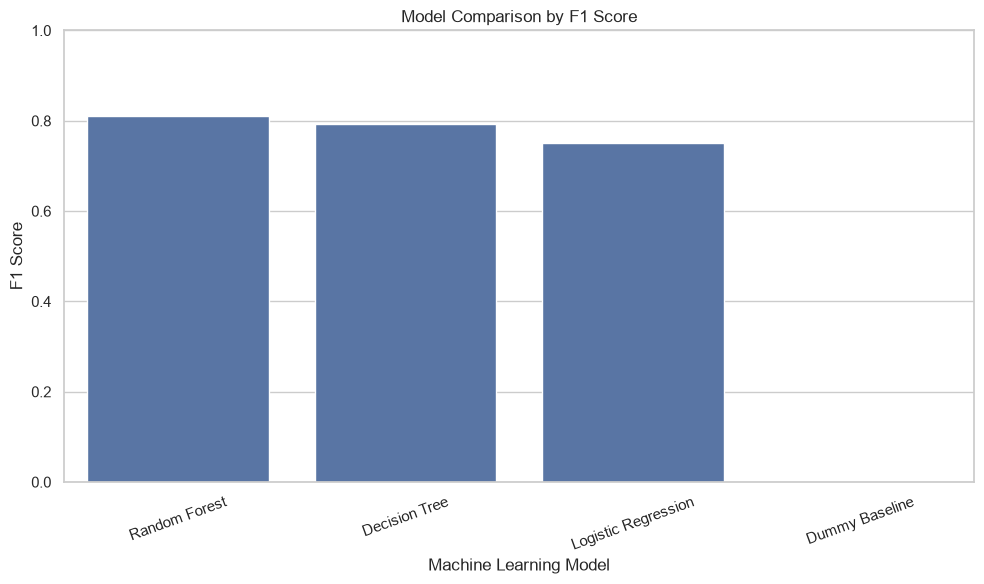

In [12]:
# ============================================================
# STEP 82 — MODEL COMPARISON VISUALIZATION
# ============================================================

print("\n" + "=" * 70)
print("STEP 82 — MODEL COMPARISON")
print("=" * 70)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="F1_Score"
)

plt.title("Model Comparison by F1 Score")
plt.xlabel("Machine Learning Model")
plt.ylabel("F1 Score")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.tight_layout()

plt.savefig(
    os.path.join(ML_FOLDER, "step_82_model_comparison.png"),
    dpi=300
)

plt.show()

In [13]:
# ============================================================
# STEP 83 — SELECT BEST MODEL
# ============================================================

print("\n" + "=" * 70)
print("STEP 83 — SELECT BEST MODEL")
print("=" * 70)

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model selected by F1 Score:", best_model_name)


STEP 83 — SELECT BEST MODEL
Best model selected by F1 Score: Random Forest



STEP 84 — CONFUSION MATRIX
Confusion Matrix:
[[13336  1697]
 [ 1670  7175]]


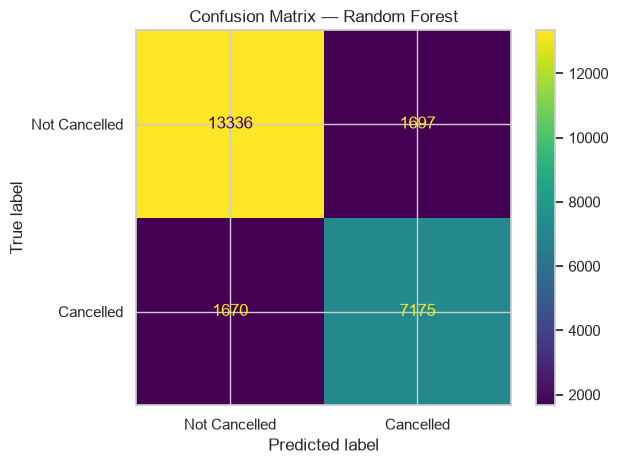

In [14]:
# ============================================================
# STEP 84 — CONFUSION MATRIX
# ============================================================

print("\n" + "=" * 70)
print("STEP 84 — CONFUSION MATRIX")
print("=" * 70)

best_predictions = best_model.predict(X_test)

cm = confusion_matrix(y_test, best_predictions)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Cancelled", "Cancelled"]
)

disp.plot(values_format="d")

plt.title("Confusion Matrix — " + best_model_name)
plt.tight_layout()

plt.savefig(
    os.path.join(ML_FOLDER, "step_84_confusion_matrix.png"),
    dpi=300
)

plt.show()


STEP 85 — ROC AND PRECISION-RECALL CURVES


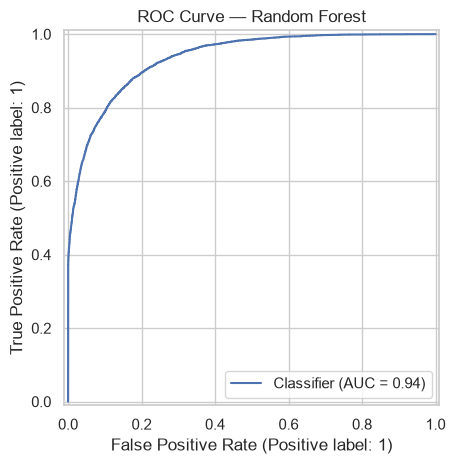

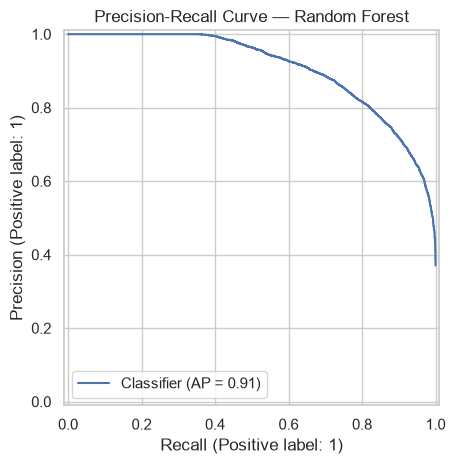

In [15]:
# ============================================================
# STEP 85 — ROC AND PRECISION-RECALL CURVES
# ============================================================

print("\n" + "=" * 70)
print("STEP 85 — ROC AND PRECISION-RECALL CURVES")
print("=" * 70)

best_probabilities = None

if hasattr(best_model, "predict_proba"):

    best_probabilities = best_model.predict_proba(X_test)[:, 1]

    RocCurveDisplay.from_predictions(
        y_test,
        best_probabilities
    )

    plt.title("ROC Curve — " + best_model_name)
    plt.tight_layout()

    plt.savefig(
        os.path.join(ML_FOLDER, "step_85_roc_curve.png"),
        dpi=300
    )

    plt.show()

    PrecisionRecallDisplay.from_predictions(
        y_test,
        best_probabilities
    )

    plt.title("Precision-Recall Curve — " + best_model_name)
    plt.tight_layout()

    plt.savefig(
        os.path.join(ML_FOLDER, "step_85_precision_recall_curve.png"),
        dpi=300
    )

    plt.show()

else:
    print("Selected model does not provide probabilities.")


STEP 86 — FEATURE IMPORTANCE
Top 20 important features:
                                Feature  Importance
275        cat__deposit_type_No Deposit    0.104964
0                        num__lead_time    0.094180
197                    cat__country_PRT    0.094051
276        cat__deposit_type_Non Refund    0.085243
18       num__total_of_special_requests    0.068245
17     num__required_car_parking_spaces    0.041025
13                           num__agent    0.037226
10          num__previous_cancellations    0.034130
16                             num__adr    0.032256
246       cat__market_segment_Online TA    0.030512
280        cat__customer_type_Transient    0.026426
245   cat__market_segment_Offline TA/TO    0.026397
12                 num__booking_changes    0.021760
263           cat__assigned_room_type_A    0.019928
244          cat__market_segment_Groups    0.019917
281  cat__customer_type_Transient-Party    0.018820
19                    num__total_nights    0.016513
251    

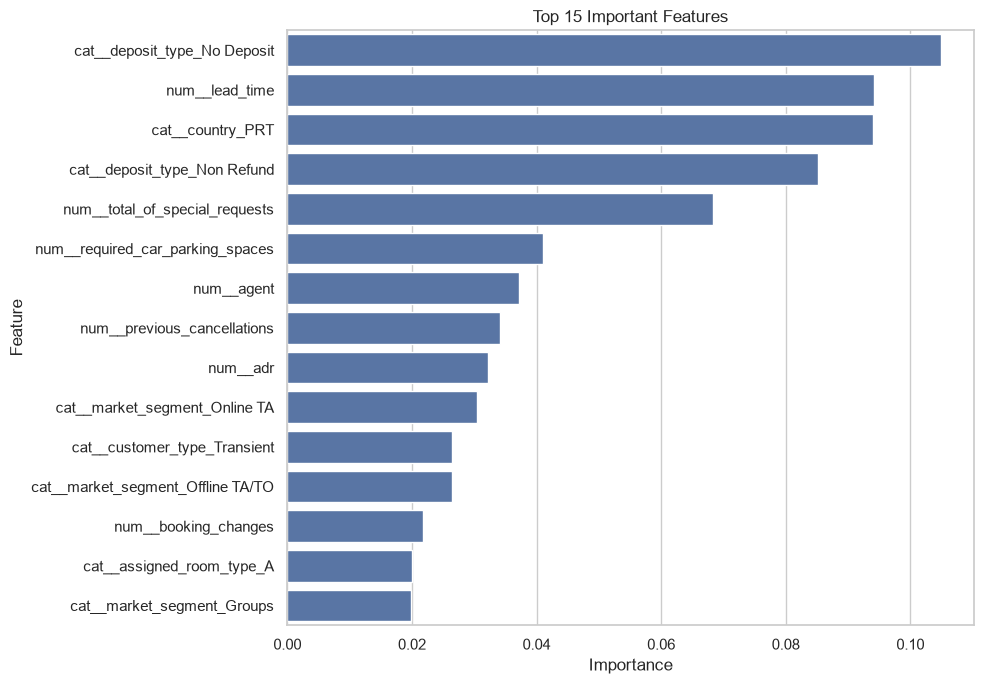

In [16]:
# ============================================================
# STEP 86 — FEATURE IMPORTANCE
# ============================================================

print("\n" + "=" * 70)
print("STEP 86 — FEATURE IMPORTANCE")
print("=" * 70)

model_object = best_model.named_steps["model"]

importance_df = pd.DataFrame()

if hasattr(model_object, "feature_importances_"):

    feature_names = best_model.named_steps[
        "prep"
    ].get_feature_names_out()

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": model_object.feature_importances_
    }).sort_values(
        "Importance",
        ascending=False
    )

    print("Top 20 important features:")
    print(importance_df.head(20))

    importance_df.to_csv(
        os.path.join(ML_FOLDER, "step_86_feature_importance.csv"),
        index=False
    )

    plt.figure(figsize=(10, 7))

    sns.barplot(
        data=importance_df.head(15),
        x="Importance",
        y="Feature"
    )

    plt.title("Top 15 Important Features")
    plt.tight_layout()

    plt.savefig(
        os.path.join(ML_FOLDER, "step_86_feature_importance.png"),
        dpi=300
    )

    plt.show()

elif hasattr(model_object, "coef_"):

    feature_names = best_model.named_steps[
        "prep"
    ].get_feature_names_out()

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Coefficient": model_object.coef_[0],
        "Absolute_Importance": abs(model_object.coef_[0])
    }).sort_values(
        "Absolute_Importance",
        ascending=False
    )

    print("Top 20 features by absolute coefficient:")
    print(importance_df.head(20))

    importance_df.to_csv(
        os.path.join(ML_FOLDER, "step_86_feature_importance.csv"),
        index=False
    )

else:
    print("Feature importance is not available for this model.")

In [17]:
# ============================================================
# STEP 87 — SAVE MODEL AND TEST PREDICTIONS
# ============================================================

print("\n" + "=" * 70)
print("STEP 87 — SAVE MODEL AND PREDICTIONS")
print("=" * 70)

MODEL_FILE = os.path.join(
    ML_FOLDER,
    "best_hotel_cancellation_model.pkl"
)

joblib.dump(best_model, MODEL_FILE)

print("Model saved:", MODEL_FILE)

prediction_df = X_test.copy()

prediction_df["Actual_Cancellation"] = y_test.to_numpy()
prediction_df["Predicted_Cancellation"] = best_predictions

if best_probabilities is not None:
    prediction_df["Cancellation_Probability"] = best_probabilities

PREDICTION_FILE = os.path.join(
    ML_FOLDER,
    "step_87_test_predictions.csv"
)

prediction_df.to_csv(
    PREDICTION_FILE,
    index=False
)

print("Predictions saved:", PREDICTION_FILE)


STEP 87 — SAVE MODEL AND PREDICTIONS
Model saved: output\machine_learning_results\best_hotel_cancellation_model.pkl
Predictions saved: output\machine_learning_results\step_87_test_predictions.csv


In [18]:
# ============================================================
# STEP 88 — FINAL METRICS AND BUSINESS INSIGHTS
# ============================================================

print("\n" + "=" * 70)
print("STEP 88 — FINAL METRICS AND BUSINESS INSIGHTS")
print("=" * 70)

final_metrics = {
    "Best_Model": best_model_name,
    "Accuracy": accuracy_score(y_test, best_predictions),
    "Precision": precision_score(
        y_test, best_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, best_predictions, zero_division=0
    ),
    "F1_Score": f1_score(
        y_test, best_predictions, zero_division=0
    ),
    "Cancellation_Rate_Percentage": df[target_column].mean() * 100
}

metrics_df = pd.DataFrame(
    list(final_metrics.items()),
    columns=["Metric", "Value"]
)

print(metrics_df)

metrics_df.to_csv(
    os.path.join(ML_FOLDER, "step_88_final_metrics.csv"),
    index=False
)

business_insights = []

business_insights.append(
    "Overall cancellation rate: "
    + str(round(df[target_column].mean() * 100, 2))
    + "%"
)

if "hotel" in df.columns:

    hotel_rates = (
        df.groupby("hotel")[target_column]
        .mean()
        .mul(100)
        .round(2)
    )

    business_insights.append(
        "Cancellation rate by hotel:\n"
        + hotel_rates.to_string()
    )

if "customer_type" in df.columns:

    customer_rates = (
        df.groupby("customer_type")[target_column]
        .mean()
        .mul(100)
        .round(2)
    )

    business_insights.append(
        "Cancellation rate by customer type:\n"
        + customer_rates.to_string()
    )

if "deposit_type" in df.columns:

    deposit_rates = (
        df.groupby("deposit_type")[target_column]
        .mean()
        .mul(100)
        .round(2)
    )

    business_insights.append(
        "Cancellation rate by deposit type:\n"
        + deposit_rates.to_string()
    )

business_insights.append(
    "Best model based on F1 Score: " + best_model_name
)

print("\nBUSINESS INSIGHTS")

for insight in business_insights:
    print("\n" + insight)

with open(
    os.path.join(ML_FOLDER, "step_88_business_insights.txt"),
    "w",
    encoding="utf-8"
) as file:

    file.write("\n\n".join(business_insights))


STEP 88 — FINAL METRICS AND BUSINESS INSIGHTS
                         Metric          Value
0                    Best_Model  Random Forest
1                      Accuracy       0.858992
2                     Precision       0.808724
3                        Recall       0.811193
4                      F1_Score       0.809957
5  Cancellation_Rate_Percentage      37.041628

BUSINESS INSIGHTS

Overall cancellation rate: 37.04%

Cancellation rate by hotel:
hotel
City Hotel - Ahmedabad       42.28
City Hotel - Bangalore       43.24
City Hotel - Bhopal          40.64
City Hotel - Chandigarh      41.60
City Hotel - Chennai         41.36
City Hotel - Delhi           41.28
City Hotel - Goa             41.50
City Hotel - Hyderabad       42.29
City Hotel - Indore          41.80
City Hotel - Jaipur          41.21
City Hotel - Kochi           40.92
City Hotel - Kolkata         42.57
City Hotel - Lucknow         41.93
City Hotel - Mumbai          41.60
City Hotel - Pune            41.68
Resort Hot

In [19]:
# ============================================================
# STEP 89 — GENERATE FINAL PROJECT REPORT
# ============================================================

print("\n" + "=" * 70)
print("STEP 89 — FINAL PROJECT REPORT")
print("=" * 70)

report = f"""
HOTEL BOOKING CANCELLATION PREDICTION & ANALYSIS
================================================

DATASET SUMMARY
---------------
Total records: {len(df)}
Total columns: {df.shape[1]}
Cancelled bookings: {(df[target_column] == 1).sum()}
Not cancelled bookings: {(df[target_column] == 0).sum()}
Cancellation rate: {df[target_column].mean() * 100:.2f}%

MODEL COMPARISON
----------------
{results_df.to_string(index=False)}

BEST MODEL
----------
{best_model_name}

FINAL TEST METRICS
------------------
{metrics_df.to_string(index=False)}

BUSINESS INSIGHTS
-----------------
{chr(10).join(business_insights)}

CONCLUSION
----------
This project analyzes hotel booking cancellations using data
preprocessing, statistical analysis, visualizations, and machine
learning models.

The model predicts cancellation risk from the available booking
features. The results may support hotel booking and revenue planning.

IMPORTANT
---------
The reported metrics come from the test split used in this run.
Prediction performance can vary with the dataset and model settings.
The model should be validated before operational use.
"""

REPORT_FILE = os.path.join(
    ML_FOLDER,
    "step_89_final_project_report.txt"
)

with open(
    REPORT_FILE,
    "w",
    encoding="utf-8"
) as file:
    file.write(report)

print(report)
print("Final report saved:", REPORT_FILE)


STEP 89 — FINAL PROJECT REPORT

HOTEL BOOKING CANCELLATION PREDICTION & ANALYSIS

DATASET SUMMARY
---------------
Total records: 119390
Total columns: 37
Cancelled bookings: 44224
Not cancelled bookings: 75166
Cancellation rate: 37.04%

MODEL COMPARISON
----------------
              Model  Accuracy  Precision   Recall  F1_Score  ROC_AUC   PR_AUC
      Random Forest  0.858992   0.808724 0.811193  0.809957 0.935597 0.908098
      Decision Tree  0.843747   0.779759 0.805766  0.792549 0.925885 0.882464
Logistic Regression  0.808694   0.726320 0.775919  0.750301 0.894282 0.852158
     Dummy Baseline  0.629575   0.000000 0.000000  0.000000 0.500000 0.370425

BEST MODEL
----------
Random Forest

FINAL TEST METRICS
------------------
                      Metric         Value
                  Best_Model Random Forest
                    Accuracy      0.858992
                   Precision      0.808724
                      Recall      0.811193
                    F1_Score      0.809957
Canc

In [20]:
# ============================================================
# STEP 90 — FINAL PROJECT SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("STEP 90 — PROJECT COMPLETION SUMMARY")
print("=" * 70)

print("\nDataset Shape:", df.shape)

print("\nCancellation Rate:")
print(round(df[target_column].mean() * 100, 2), "%")

print("\nBest Model:", best_model_name)

print("\nModel Performance:")
print(results_df)

print("\nPreprocessing Folder:")
print(os.path.abspath(PREPROCESSING_FOLDER))

print("\nEDA Folder:")
print(os.path.abspath(EDA_FOLDER))

print("\nVisualization Folder:")
print(os.path.abspath(VISUALIZATION_FOLDER))

print("\nMachine Learning Folder:")
print(os.path.abspath(ML_FOLDER))

print("\nGenerated Files:")

for root, dirs, files in os.walk(OUTPUT_FOLDER):

    for filename in sorted(files):
        print(os.path.join(root, filename))

print("\n" + "=" * 70)
print("HOTEL BOOKING PROJECT COMPLETED SUCCESSFULLY!")
print("MEMBER 2 — STEPS 1–21 COMPLETED")
print("MEMBER 3 — STEPS 22–56 COMPLETED")
print("MEMBER 4 — STEPS 57–70 COMPLETED")
print("MEMBER 5 — STEPS 71–90 COMPLETED")
print("=" * 70)


STEP 90 — PROJECT COMPLETION SUMMARY

Dataset Shape: (119390, 37)

Cancellation Rate:
37.04 %

Best Model: Random Forest

Model Performance:
                 Model  Accuracy  Precision    Recall  F1_Score   ROC_AUC  \
3        Random Forest  0.858992   0.808724  0.811193  0.809957  0.935597   
2        Decision Tree  0.843747   0.779759  0.805766  0.792549  0.925885   
1  Logistic Regression  0.808694   0.726320  0.775919  0.750301  0.894282   
0       Dummy Baseline  0.629575   0.000000  0.000000  0.000000  0.500000   

     PR_AUC  
3  0.908098  
2  0.882464  
1  0.852158  
0  0.370425  

Preprocessing Folder:
C:\Users\admin\OneDrive\Desktop\Hotel Booking Cancellation Prediction & Analysis\output\preprocessing_results

EDA Folder:
C:\Users\admin\OneDrive\Desktop\Hotel Booking Cancellation Prediction & Analysis\output\eda_results

Visualization Folder:
C:\Users\admin\OneDrive\Desktop\Hotel Booking Cancellation Prediction & Analysis\output\visualization_results

Machine Learning Folde